saved
contrast     rings=0.484  noise=8.507
homogeneity  rings=0.775  noise=0.324
energy       rings=0.264  noise=0.132
correlation  rings=0.905  noise=0.012


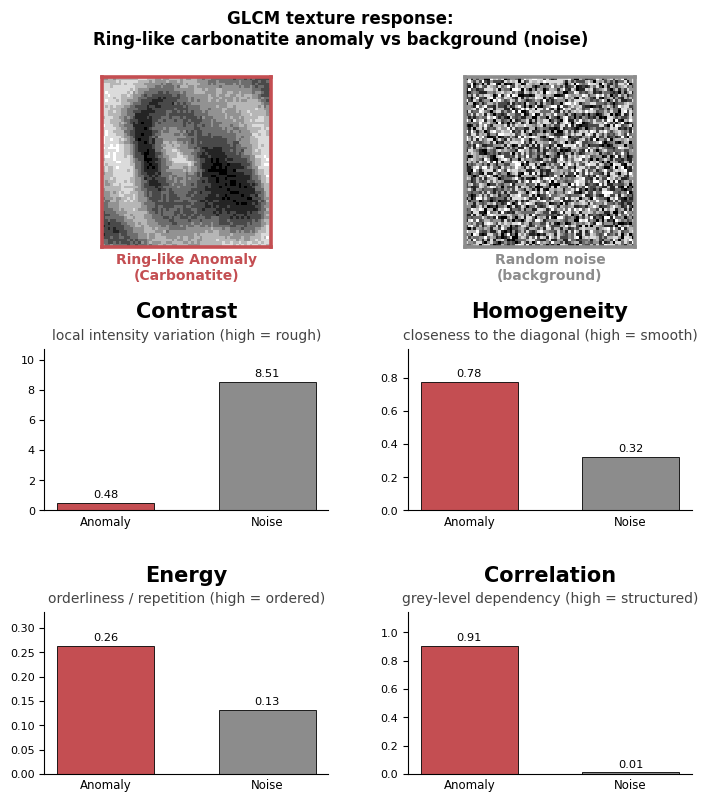

In [1]:
"""
GLCM principle demo -- Irregular Natural Anomaly vs Noise (background)
Layout: 3 rows x 2 cols. Row 1 = the two patches; rows 2-3 = 2x2 property bars.
Same GLCM parameters as the thesis pipeline.
Deps: numpy, matplotlib, scikit-image
"""
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops

# ---- GLCM params (identical to add_glcm_features) ----
LEVELS = 8
DIST   = [1]
ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]
PROPS  = ['contrast', 'homogeneity', 'energy', 'correlation']
N = 61   # visualisation patch size (real pipeline window is 9x9)

def quantize(a):
    a = a.astype(float)
    a = (a - a.min()) / (a.max() - a.min() + 1e-9)
    return np.round(a * (LEVELS - 1)).astype(np.uint8)

def glcm_props(q):
    g = graycomatrix(q, distances=DIST, angles=ANGLES,
                     levels=LEVELS, symmetric=True, normed=True)
    return {p: float(graycoprops(g, p).mean()) for p in PROPS}

# ---- two patches: natural irregular anomaly vs random noise ----
yy, xx = np.mgrid[0:N, 0:N]
cx = cy = N // 2


dx = xx - cx
dy = yy - cy
angle = np.arctan2(dy, dx)


theta = np.pi / 4  
cos_t = np.cos(theta)
sin_t = np.sin(theta)
dx_rot = dx * cos_t - dy * sin_t
dy_rot = dx * sin_t + dy * cos_t


r = np.sqrt((dx_rot * 1.5) ** 2 + (dy_rot) ** 2)


wobble = 4.0 * np.sin(dx / 5.0) + 3.0 * np.cos(dy / 6.0)
r_distorted = r + wobble


direction_mod = 0.35 + 0.65 * (0.5 + 0.5 * np.cos(2 * angle - np.pi/6))

rng = np.random.default_rng(3)


mineral_texture = 0.5 + direction_mod * 0.4 * np.cos(r_distorted / 6.0)
mineral_texture += rng.random((N, N)) * 0.15

patches = {
    'Ring-like Anomaly\n(Carbonatite)': mineral_texture,
    'Random noise\n(background)'              : rng.random((N, N)),
}

names = list(patches.keys())
COL   = {'rings': '#C44E52', 'noise': '#8C8C8C'}
qs    = [quantize(a) for a in patches.values()]
vals  = [glcm_props(q) for q in qs]                 # [rings, noise]

desc = {
    'contrast'   : 'local intensity variation (high = rough)',
    'homogeneity': 'closeness to the diagonal (high = smooth)',
    'energy'     : 'orderliness / repetition (high = ordered)',
    'correlation': 'grey-level dependency (high = structured)',
}

# ---- figure: 3 rows x 2 cols ----
plt.rcParams.update({'font.size': 10, 'font.family': 'DejaVu Sans',
                     'axes.linewidth': 0.8})
fig = plt.figure(figsize=(7.4, 8.4))
gs = fig.add_gridspec(3, 2, height_ratios=[1.05, 1.0, 1.0],
                      hspace=0.62, wspace=0.28,
                      left=0.10, right=0.975, top=0.905, bottom=0.075)

# row 1: the two patches
for j, (nm, q, key) in enumerate(zip(names, qs, ('rings', 'noise'))):
    ax = fig.add_subplot(gs[0, j])
    ax.imshow(q, cmap='gray', vmin=0, vmax=LEVELS - 1, interpolation='nearest')
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_edgecolor(COL[key]); s.set_linewidth(2.6)
    ax.set_xlabel(nm, fontsize=10, color=COL[key], fontweight='bold')
    ax.set_aspect('equal')

# rows 2-3: 2x2 property bar charts
cells = [(1, 0), (1, 1), (2, 0), (2, 1)]
xpos  = [0, 1]
for p, (gr, gc) in zip(PROPS, cells):
    ax = fig.add_subplot(gs[gr, gc])
    v = [vals[0][p], vals[1][p]]                     # rings, noise
    bars = ax.bar(xpos, v, color=[COL['rings'], COL['noise']],
                  edgecolor='black', linewidth=0.6, width=0.60)
    ax.set_title(p.capitalize(), fontsize=15, fontweight='bold', pad=22)
    ax.text(0.5, 1.04, desc[p], transform=ax.transAxes, ha='center',
            va='bottom', fontsize=10, color='#444444')
    ax.set_xticks(xpos); ax.set_xticklabels(['Anomaly', 'Noise'], fontsize=8.5)
    ax.tick_params(axis='x', length=0)
    top = max(v) * 1.26 if max(v) > 0 else 1
    ax.set_ylim(0, top)
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val + top * 0.02, f'{val:.2f}',
                ha='center', va='bottom', fontsize=8.2)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='y', labelsize=8)

fig.suptitle('GLCM texture response:\nRing-like carbonatite anomaly vs background (noise)',
             fontsize=12, fontweight='bold', y=0.985)

fig.savefig('glcm_ring-like_anomaly_vs_noise.png', dpi=1000, bbox_inches='tight')
print('saved')
for p in PROPS:
    print(f'{p:12s} rings={vals[0][p]:.3f}  noise={vals[1][p]:.3f}')